In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

In [2]:
# Load the Stock Flow dataset
StackFlow=pd.read_csv('results.csv')

In [3]:
# overview of the dataset
StackFlow.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65437 entries, 0 to 65436
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), object(100)
memory usage: 56.9+ MB


In [4]:
# overview of the data
list(StackFlow)

['ResponseId',
 'MainBranch',
 'Age',
 'Employment',
 'RemoteWork',
 'Check',
 'CodingActivities',
 'EdLevel',
 'LearnCode',
 'LearnCodeOnline',
 'TechDoc',
 'YearsCode',
 'YearsCodePro',
 'DevType',
 'OrgSize',
 'PurchaseInfluence',
 'BuyNewTool',
 'BuildvsBuy',
 'TechEndorse',
 'Country',
 'Currency',
 'CompTotal',
 'LanguageHaveWorkedWith',
 'LanguageWantToWorkWith',
 'LanguageAdmired',
 'DatabaseHaveWorkedWith',
 'DatabaseWantToWorkWith',
 'DatabaseAdmired',
 'PlatformHaveWorkedWith',
 'PlatformWantToWorkWith',
 'PlatformAdmired',
 'WebframeHaveWorkedWith',
 'WebframeWantToWorkWith',
 'WebframeAdmired',
 'EmbeddedHaveWorkedWith',
 'EmbeddedWantToWorkWith',
 'EmbeddedAdmired',
 'MiscTechHaveWorkedWith',
 'MiscTechWantToWorkWith',
 'MiscTechAdmired',
 'ToolsTechHaveWorkedWith',
 'ToolsTechWantToWorkWith',
 'ToolsTechAdmired',
 'NEWCollabToolsHaveWorkedWith',
 'NEWCollabToolsWantToWorkWith',
 'NEWCollabToolsAdmired',
 'OpSysPersonal use',
 'OpSysProfessional use',
 'OfficeStackAsyncHa

In [4]:
# Selecting the attributes that could be important for job satisfaction
JobSat = StackFlow[["Age","MainBranch","EdLevel","RemoteWork","OrgSize","WorkExp","JobSat","AISelect","JobSatPoints_1","JobSatPoints_4","JobSatPoints_5","JobSatPoints_6","JobSatPoints_7","JobSatPoints_8","JobSatPoints_9","JobSatPoints_10","JobSatPoints_11"]]

In [5]:
# Adaptation of the data so that it can be evaluated
JobSat=JobSat.replace({"Age":{"Under 18 years old":1,"18-24 years old":2,"25-34 years old":3,"35-44 years old":4,"45-54 years old":5,"55-64 years old":6,"65 years or older":7,"Prefer not to say":8}})
JobSat=JobSat.replace({"RemoteWork":{"Remote":1,"In-person":2,"Hybrid (some remote, some in-person)":3}})
JobSat=JobSat.replace({"OrgSize":{"Just me - I am a freelancer, sole proprietor, etc.":1,"2 to 9 employees":2,"10 to 19 employees":3,"20 to 99 employees":3,"100 to 499 employees":4,"500 to 999 employees":5,"1,000 to 4,999 employees":6,"5,000 to 9,999 employees":7,"10,000 or more employees":8,"I don’t know":9}})
JobSat=JobSat.replace({"AISelect":{"Yes":1,"No, but I plan to soon":2,"No, and I don't plan to":3}})
JobSat=JobSat.replace({"MainBranch":{"I am a developer by profession":1,"I am not primarily a developer, but I write code sometimes as part of my work/studies":2,"I used to be a developer by profession, but no longer am":3,"I am learning to code":4,"I code primarily as a hobby":5,"None of these":6}})
JobSat=JobSat.replace({"EdLevel":{"Primary/elementary school":1,"Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)":2,"Some college/university study without earning a degree":3,"Associate degree (A.A., A.S., etc.)":4,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)":5,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)":5,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)":6,"Something else":7}})

/tmp/ipykernel_13/2330667746.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  JobSat=JobSat.replace({"Age":{"Under 18 years old":1,"18-24 years old":2,"25-34 years old":3,"35-44 years old":4,"45-54 years old":5,"55-64 years old":6,"65 years or older":7,"Prefer not to say":8}})
/tmp/ipykernel_13/2330667746.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  JobSat=JobSat.replace({"RemoteWork":{"Remote":1,"In-person":2,"Hybrid (some remote, some in-person)":3}})
/tmp/ipykernel_13/2330667746.py:4: FutureWarning: Downcasting behavi

In [6]:
# Renaming 
JobSat = JobSat.rename(columns={'JobSatPoints_1': 'DrivingStrategy',
                                'JobSatPoints_4': 'ContributingOpenSource', 
                                'JobSatPoints_5': 'SecuringEnvironments', 
                                'JobSatPoints_6': 'ImprovingQuality', 
                                'JobSatPoints_7': 'LearningNewTechnology', 
                                'JobSatPoints_8': 'DesigningEnvironments', 
                                'JobSatPoints_9': 'BeingPowerUser', 
                                'JobSatPoints_10': 'WorkingNewHardware', 
                                'JobSatPoints_11': 'InternalNetwork '})

In [7]:
# Data wrangling 
JobSat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65437 entries, 0 to 65436
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     65437 non-null  int64  
 1   MainBranch              65437 non-null  int64  
 2   EdLevel                 60784 non-null  float64
 3   RemoteWork              54806 non-null  float64
 4   OrgSize                 47480 non-null  float64
 5   WorkExp                 29658 non-null  float64
 6   JobSat                  29126 non-null  float64
 7   AISelect                60907 non-null  float64
 8   DrivingStrategy         29324 non-null  float64
 9   ContributingOpenSource  29393 non-null  float64
 10  SecuringEnvironments    29411 non-null  float64
 11  ImprovingQuality        29450 non-null  float64
 12  LearningNewTechnology   29448 non-null  float64
 13  DesigningEnvironments   29456 non-null  float64
 14  BeingPowerUser          29456 non-null

In [8]:
# Data wrangling
JobSat.head(5)

,Age,MainBranch,EdLevel,RemoteWork,OrgSize,WorkExp,JobSat,AISelect,DrivingStrategy,ContributingOpenSource,SecuringEnvironments,ImprovingQuality,LearningNewTechnology,DesigningEnvironments,BeingPowerUser,WorkingNewHardware,InternalNetwork
0,1,1,1.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4,1,5.0,1.0,NaN,17.0,NaN,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,5,1,5.0,1.0,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,4,3.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,1,2.0,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Data wrangling
JobSat.describe()

,Age,MainBranch,EdLevel,RemoteWork,OrgSize,WorkExp,JobSat,AISelect,DrivingStrategy,ContributingOpenSource,SecuringEnvironments,ImprovingQuality,LearningNewTechnology,DesigningEnvironments,BeingPowerUser,WorkingNewHardware,InternalNetwork
count,65437.000000,65437.000000,60784.000000,54806.000000,47480.000000,29658.000000,29126.000000,60907.000000,29324.000000,29393.000000,29411.000000,29450.000000,29448.00000,29456.000000,29456.000000,29450.000000,29445.000000
mean,3.315250,1.527102,4.436957,2.039850,4.301179,11.466957,6.935041,1.625248,18.581094,7.522140,10.060857,24.343232,22.96522,20.278165,16.169432,10.955713,9.953948
std,1.244719,1.123449,1.218846,0.893559,2.121358,9.168709,2.088259,0.849427,25.966221,18.422661,21.833836,27.089360,27.01774,26.108110,24.845032,22.906263,21.775652
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,1.000000,4.000000,1.000000,3.000000,4.000000,6.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,1.000000,5.000000,2.000000,4.000000,9.000000,7.000000,1.000000,10.000000,0.000000,0.000000,20.000000,15.00000,10.000000,5.000000,0.000000,0.000000
75%,4.000000,1.000000,5.000000,3.000000,6.000000,16.000000,8.000000,2.000000,22.000000,5.000000,10.000000,30.000000,30.00000,25.000000,20.000000,10.000000,10.000000
max,8.000000,5.000000,7.000000,3.000000,9.000000,50.000000,10.000000,3.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000


In [10]:
# Data wrangling
JobSat.isna().sum()

Age                           0
MainBranch                    0
EdLevel                    4653
RemoteWork                10631
OrgSize                   17957
WorkExp                   35779
JobSat                    36311
AISelect                   4530
DrivingStrategy           36113
ContributingOpenSource    36044
SecuringEnvironments      36026
ImprovingQuality          35987
LearningNewTechnology     35989
DesigningEnvironments     35981
BeingPowerUser            35981
WorkingNewHardware        35987
InternalNetwork           35992
dtype: int64

In [11]:
# Data wrangling
JobSat=JobSat.dropna()

In [12]:
# Data wrangling
JobSat.isna().sum()

Age                       0
MainBranch                0
EdLevel                   0
RemoteWork                0
OrgSize                   0
WorkExp                   0
JobSat                    0
AISelect                  0
DrivingStrategy           0
ContributingOpenSource    0
SecuringEnvironments      0
ImprovingQuality          0
LearningNewTechnology     0
DesigningEnvironments     0
BeingPowerUser            0
WorkingNewHardware        0
InternalNetwork           0
dtype: int64

In [13]:
# cleaned Data
JobSat.head()

,Age,MainBranch,EdLevel,RemoteWork,OrgSize,WorkExp,JobSat,AISelect,DrivingStrategy,ContributingOpenSource,SecuringEnvironments,ImprovingQuality,LearningNewTechnology,DesigningEnvironments,BeingPowerUser,WorkingNewHardware,InternalNetwork
72,2,1,2.0,3.0,4.0,3.0,10.0,1.0,90.0,10.0,75.0,65.0,100.0,100.0,100.0,50.0,90.0
379,4,1,5.0,1.0,3.0,7.0,10.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
386,4,1,5.0,1.0,7.0,14.0,7.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
389,3,1,3.0,1.0,3.0,8.0,10.0,1.0,10.0,0.0,0.0,20.0,30.0,5.0,20.0,10.0,5.0
392,4,1,6.0,3.0,6.0,18.0,7.0,1.0,40.0,0.0,10.0,30.0,5.0,10.0,0.0,0.0,5.0


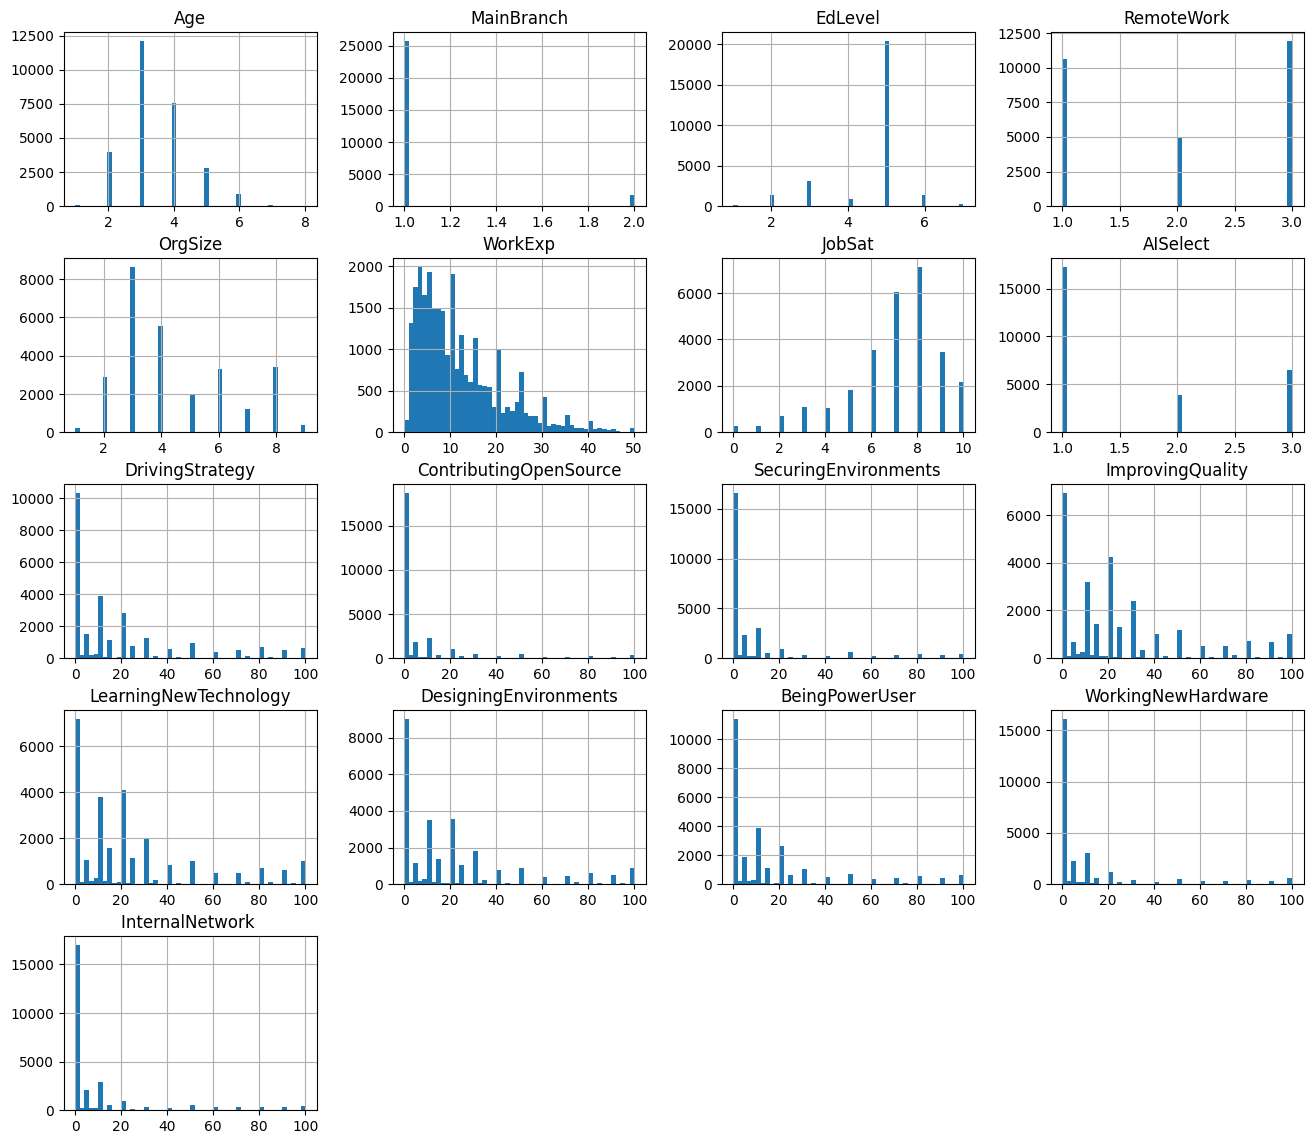

In [14]:
# Overview of the cleaned data
JobSat.hist(bins=50, figsize=(16, 14))
plt.show()

In [15]:
# Export the relvant data
export_csv = JobSat.to_csv ('JobSatisfaction_reduced.csv',index=False,header=True)

In [16]:
# Correlation JobSat
corr_JobSat = JobSat.corr()

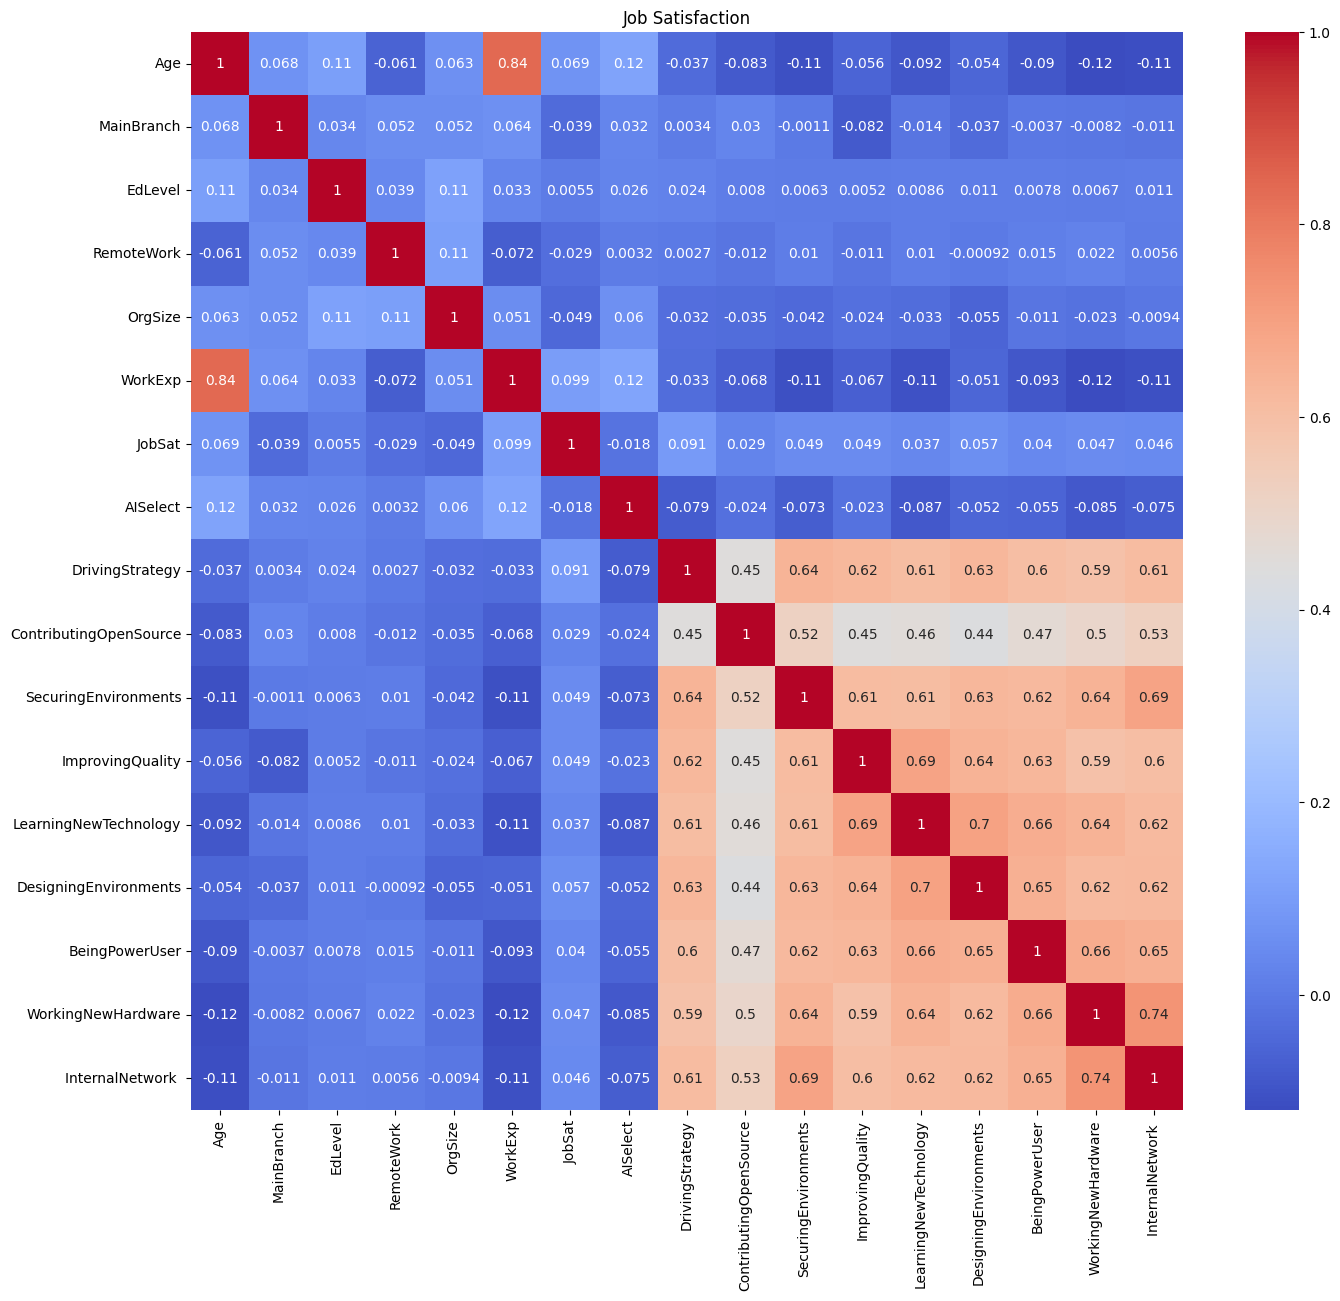

In [17]:
# Heatmap for a better overview
plt.figure(figsize=(16, 14))
sns.heatmap(corr_JobSat, annot=True, cmap='coolwarm')
plt.title('Job Satisfaction')
plt.show()

In [18]:
# Correlation wich attribute is correlated for Job Satifaction
corr_JobSat["JobSat"].sort_values(ascending = False)

JobSat                    1.000000
WorkExp                   0.099092
DrivingStrategy           0.090935
Age                       0.069268
DesigningEnvironments     0.057131
SecuringEnvironments      0.049115
ImprovingQuality          0.048631
WorkingNewHardware        0.046623
InternalNetwork           0.045872
BeingPowerUser            0.040118
LearningNewTechnology     0.036635
ContributingOpenSource    0.028702
EdLevel                   0.005530
AISelect                 -0.018169
RemoteWork               -0.028693
MainBranch               -0.039437
OrgSize                  -0.049028
Name: JobSat, dtype: float64

In [19]:
# Split the data into x and y 
X = JobSat.drop("JobSat", axis=1)
y = JobSat["JobSat"]

In [20]:
# Split data in test and train sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

In [21]:
# linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [22]:
# prediction 
model_pred_train = model.predict(X_train)
model_pred_test = model.predict(X_test)

In [23]:
# Root mean square from the train and test set
rmse_train = root_mean_squared_error(y_train, model_pred_train)
print(rmse_train)
rmse_test = root_mean_squared_error(y_test, model_pred_test)
print(rmse_test)

2.040905416648415
2.072801936445228


In [24]:
# calculate r2 score for predictions Linear Regression
r2_train = r2_score(y_train, model_pred_train)
print("The R2 value for the train set Linear Regression is {}.".format(round(r2_train,2)))
r2_test = r2_score(y_test, model_pred_test)
print("The R2 value for the test set Linear Regression is {}.".format(round(r2_test,2)))

The R2 value for the train set Linear Regression is 0.03.
The R2 value for the test set Linear Regression is 0.02.


In [26]:
# Decision Tree depth = 30
model_DT_30 = DecisionTreeClassifier(max_depth=30)
model_DT_30.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=30)

In [27]:
# prediction Decision Tree depth = 30
model_pred_train = model_DT_30.predict(X_train)
model_pred_test = model_DT_30.predict(X_test)

In [28]:
# Root mean square from the train and test set
rmse_train = root_mean_squared_error(y_train, model_pred_train)
print(rmse_train)
rmse_test = root_mean_squared_error(y_test, model_pred_test)
print(rmse_test)

0.8198417463253626
2.887797839129486


In [29]:
# Calculate r2 for predictions Decision Tree depth=30
r2_train = r2_score(y_train, model_pred_train)
print("The R2 value for the train set Decision Tree depth=30 is {}.".format(round(r2_train,2)))
r2_test = r2_score(y_test, model_pred_test)
print("The R2 value for the test set Decision Tree depth=30 is {}.".format(round(r2_test,2)))

The R2 value for the train set Decision Tree depth=30 is 0.84.
The R2 value for the test set Decision Tree depth=30 is -0.9.


In [30]:
# Decision Tree depth = 5
model_DT_5 = DecisionTreeClassifier(max_depth=5)
model_DT_5.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5)

In [31]:
# prediction Decision Tree depth = 5
model_pred_train = model_DT_5.predict(X_train)
model_pred_test = model_DT_5.predict(X_test)

In [32]:
# calculate r2 for predictions Decision Tree depth = 5
r2_train = r2_score(y_train, model_pred_train)
print("The R2 value for the train set Decision Tree depth=5 is {}.".format(round(r2_train,2)))
r2_test = r2_score(y_test, model_pred_test)
print("The R2 value for the test set Decision Tree depth=5 is {}.".format(round(r2_test,2)))

The R2 value for the train set Decision Tree depth=5 is -0.2.
The R2 value for the test set Decision Tree depth=5 is -0.21.


In [33]:
# Support Vector Regression
model_SVR = SVR()
model_SVR.fit(X_train, y_train)

SVR()

In [34]:
# prediction SVR
model_pred_train = model_SVR.predict(X_train)
model_pred_test = model_SVR.predict(X_test)

In [35]:
# calculate r2 for predictions
r2_train = r2_score(y_train, model_pred_train)
print("The R2 value for the train set SVR is {}.".format(round(r2_train,2)))
r2_test = r2_score(y_test, model_pred_test)
print("The R2 value for the test set SVR is {}.".format(round(r2_test,2)))

The R2 value for the train set SVR is 0.04.
The R2 value for the test set SVR is 0.0.


In [36]:
# Random Forest Regressor
model_RFR = RandomForestRegressor(n_estimators=100)
model_RFR.fit(X_train, y_train)

RandomForestRegressor()

In [37]:
# prediction RFR
model_pred_train = model_RFR.predict(X_train)
model_pred_test = model_RFR.predict(X_test)

In [38]:
# calculate r2 for predictions RFR
r2_train = r2_score(y_train, model_pred_train)
print("The R2 value for the train set RFR is {}.".format(round(r2_train,2)))
r2_test = r2_score(y_test, model_pred_test)
print("The R2 value for the test set RFR is {}.".format(round(r2_test,2)))

The R2 value for the train set RFR is 0.81.
The R2 value for the test set RFR is -0.04.
